In [2]:
import sys
sys.path.append("..")

from project1.data import load_data, EMOTIONS
from collections import Counter, OrderedDict
import part1
from project1 import encoders, experiments
import numpy as np

In [3]:
# loading data and print data info

dataset, outcome_space = load_data(test_size=0.2, seed=0)

train_texts  = dataset["train"]["text"]
train_labels = dataset["train"]["label"]
pairs  = list(zip(train_texts, train_labels))   

print(dataset)                              
print("example sentence:" , dataset["train"][0])                   
print("class id and their counts:", Counter(dataset["train"]["label"]))   
print("outcome space:", [outcome_space.name(i) for i in range(len(EMOTIONS))]) 
print("first 20 (text, label) pairs:", pairs[0:20])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 6012
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1504
    })
})
example sentence: {'text': 'Grovelling people.', 'label': 4}
class id and their counts: Counter({0: 877, 1: 868, 5: 863, 3: 858, 6: 853, 2: 848, 4: 845})
outcome space: ['joy', 'fear', 'anger', 'sadness', 'disgust', 'shame', 'guilt']
first 20 (text, label) pairs: [('Grovelling people.', 4), ('My sweatheart were away on a trip, and then she got problems.', 3), ('When a close friend, residing in the hostel, lost his father I  \nreally pittied him and the situation made me feel sad.', 3), ('Receiving a postcard form my sweetheart who was abroad on  \nvacation, not being at all sure if he would write me or not.', 0), ('When my father made my mother go through really terrible  \nsituations, I felt furious, impotent, nervous, upset, ........', 2), ('When I realized that I was far behind the others in th

In [4]:
# implement tokenizer and encoders
tokenizer = part1.experiment.train_tokenizer(
  train_texts,
  vocab_size=5000,
  min_frequency=2
)

In [5]:
# encoder representations
representations = {
  "indicator": encoders.TokenIndicator(tokenizer),
  "bow": encoders.BagOfWords(tokenizer),
  "tfidf": encoders.TfIdf(tokenizer, train_texts)
}

# classification architectures --- we choose dropout 0.5 weight decay 0.1
architectures = {
    "logistic": dict(model_option="logistic", loglin_args={"max_iter": 200}),
    "mlp": dict(model_option="mlp", smlp_args=dict(hidden_dim=128, dropout=.5, weight_decay=.1, num_epochs=20)),
    "mlp_tuned": dict(model_option="mlp2", mlp2_args=dict(hidden_dim=128, second_hidden_dim=64, patience=3, dropout=.5, weight_decay=.1, num_epochs=20)),
}

In [6]:
# run experiments on all combinations of representations and architectures
my_classifiers = experiments.run_experiments(representations, architectures, pairs, outcome_space, seeds=(0,1,2))

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/lin

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/lin

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/eline/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/lin

... (118 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9341 | train acc: 0.2200 | val loss: 1.9069 | val acc: 0.3918
Epoch 02 | train loss: 1.8148 | train acc: 0.5358 | val loss: 1.7625 | val acc: 0.5200
Epoch 03 | train loss: 1.5355 | train acc: 0.6518 | val loss: 1.5683 | val acc: 0.5399
Epoch 04 | train loss: 1.2172 | train acc: 0.7299 | val loss: 1.4352 | val acc: 0.5483
Epoch 05 | train loss: 0.9581 | train acc: 0.7938 | val loss: 1.3648 | val acc: 0.5441
Epoch 06 | train loss: 0.7797 | train acc: 0.8297 | val loss: 1.3354 | val acc: 0.5466
Epoch 07 | train loss: 0.6358 | train acc: 0.8678 | val loss: 1.3290 | val acc: 0.5474
Epoch 08 | train loss: 0.5248 | train acc: 0.9000 | val loss: 1.3385 | val acc: 0.5458
Epoch 09 | train loss: 0.4424 | train acc: 0.9210 | val loss: 1.3607 | val acc: 0.5374
Epoch 10 | train loss: 0.3775 | train acc: 0.9403 | val loss: 1.3840 | val acc: 0.5366
Epoch 11 | train loss: 0.3185 | train acc: 0.9511 | val loss: 1.4142 | val acc: 0.5324
Epoch 12 | train loss: 0.2754 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9354 | train acc: 0.2021 | val loss: 1.9130 | val acc: 0.3636
Epoch 02 | train loss: 1.8245 | train acc: 0.5191 | val loss: 1.7719 | val acc: 0.4842
Epoch 03 | train loss: 1.5463 | train acc: 0.6393 | val loss: 1.5683 | val acc: 0.5300
Epoch 04 | train loss: 1.2206 | train acc: 0.7293 | val loss: 1.4228 | val acc: 0.5341
Epoch 05 | train loss: 0.9698 | train acc: 0.7865 | val loss: 1.3518 | val acc: 0.5358
Epoch 06 | train loss: 0.7751 | train acc: 0.8376 | val loss: 1.3129 | val acc: 0.5441
Epoch 07 | train loss: 0.6310 | train acc: 0.8694 | val loss: 1.3039 | val acc: 0.5549
Epoch 08 | train loss: 0.5197 | train acc: 0.9004 | val loss: 1.3087 | val acc: 0.5491
Epoch 09 | train loss: 0.4424 | train acc: 0.9187 | val loss: 1.3230 | val acc: 0.5474
Epoch 10 | train loss: 0.3714 | train acc: 0.9385 | val loss: 1.3464 | val acc: 0.5433
Epoch 11 | train loss: 0.3224 | train acc: 0.9493 | val loss: 1.3649 | val acc: 0.5458
Epoch 12 | train loss: 0.2729 | train acc: 

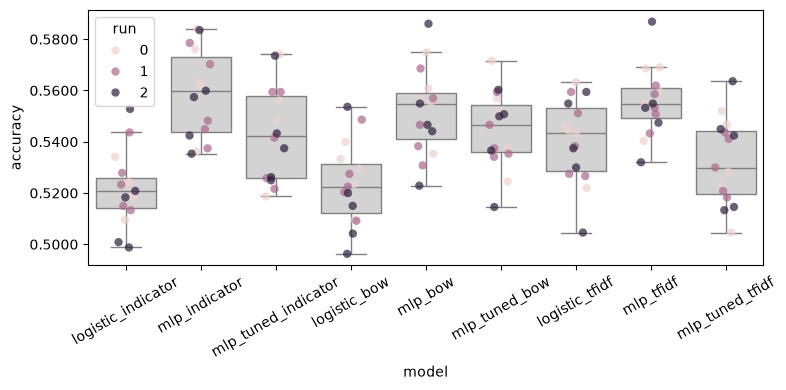

In [7]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

A=logistic_indicator B=mlp_indicator: P(A wins)=0.0000 P(Tie)=0.0001 P(B wins)=0.9999 Effect Size=6.10


,A,B,acc_A,acc_B,diff (B-A),P(A wins),P(tie),P(B wins),effect size,most probable
0,logistic_indicator,mlp_indicator,0.5217,0.5586,0.0369,0.0000,0.0001,0.9999,6.1040,mlp_indicator wint
1,logistic_indicator,mlp_tuned_indicator,0.5217,0.5435,0.0218,0.0010,0.0149,0.9841,3.0916,mlp_tuned_indicator wint
2,logistic_indicator,logistic_bow,0.5217,0.5235,0.0018,0.1036,0.6218,0.2746,0.3543,gelijk
3,logistic_indicator,mlp_bow,0.5217,0.5519,0.0302,0.0000,0.0004,0.9996,5.1239,mlp_bow wint
4,logistic_indicator,mlp_tuned_bow,0.5217,0.5445,0.0228,0.0011,0.0145,0.9844,3.0676,mlp_tuned_bow wint
5,logistic_indicator,logistic_tfidf,0.5217,0.5405,0.0189,0.0001,0.0052,0.9947,4.0164,logistic_tfidf wint
6,logistic_indicator,mlp_tfidf,0.5217,0.5557,0.0340,0.0000,0.0000,1.0000,6.4915,mlp_tfidf wint
7,logistic_indicator,mlp_tuned_tfidf,0.5217,0.5325,0.0108,0.0169,0.1839,0.7993,1.6096,mlp_tuned_tfidf wint
8,mlp_indicator,mlp_tuned_indicator,0.5586,0.5435,-0.0151,0.9820,0.0178,0.0002,-3.4714,mlp_indicator wint
9,mlp_indicator,logistic_bow,0.5586,0.5235,-0.0351,0.9999,0.0001,0.0000,-5.6186,mlp_indicator wint


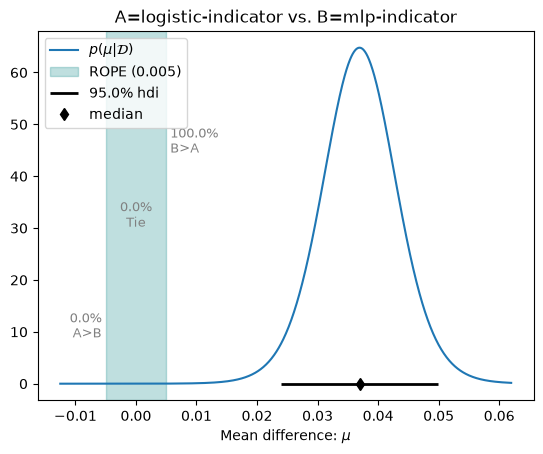

In [9]:
from itertools import combinations
import pandas as pd

# First, a little helper, to gather all accuracies across runs and folds
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])

############################################################################################################################################
# visualization of 1 setting
############################################################################################################################################

# this will have shape [num_runs, num_folds]
get_all_measurements_for(my_classifiers, 'logistic_indicator')

posterior = part1.analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, 'logistic_indicator').flatten(),  # [num_runs * num_folds]
    get_all_measurements_for(my_classifiers, 'mlp_indicator').flatten(),  # [num_runs * num_folds]
    runs=get_all_measurements_for(my_classifiers, 'logistic_indicator').shape[0],
    names=["logistic-indicator", "mlp-indicator"]
)
p_a, p_tie, p_b = posterior.probs(0.005) # rope = 0.5%
print(f"A=logistic_indicator B=mlp_indicator: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
# if you need to zoom in or out reduce/increase the argument rope_factor (it doesn't affect the ROPE, only the visualisation of it)
_ = posterior.plot(0.005)  

############################################################################################################################################

def compare_all(data, rope=0.005, plot=False):
    rows = []
    for a, b in combinations(data.keys(), 2):
        acc_a = get_all_measurements_for(data, a)
        acc_b = get_all_measurements_for(data, b)

        posterior = part1.analysis.BenavoliCorrelatedT(
            acc_a.flatten(), acc_b.flatten(),
            runs=acc_a.shape[0],   # number of seeds
            names=[a, b]
        )
        p_a, p_tie, p_b = posterior.probs(rope)
        verdict = {0: f"{a} wint", 1: "gelijk", 2: f"{b} wint"}[int(np.argmax([p_a, p_tie, p_b]))]

        rows.append({
            "A": a, "B": b,
            "acc_A": acc_a.mean(), "acc_B": acc_b.mean(),
            "diff (B-A)": posterior.mean_diff,
            "P(A wins)": p_a, "P(tie)": p_tie, "P(B wins)": p_b,
            "effect size": posterior.effect_size,
            "most probable": verdict,
        })

        if plot:
            posterior.plot(rope)
            plt.show()

    return pd.DataFrame(rows)

results_df = compare_all(my_classifiers, rope=0.005)
results_df.round(4)

              precision    recall  f1-score   support

         joy      0.635     0.657     0.646       175
        fear      0.687     0.644     0.665       174
       anger      0.451     0.467     0.459       169
     sadness      0.553     0.547     0.550       172
     disgust      0.492     0.515     0.503       169
       shame      0.413     0.410     0.412       173
       guilt      0.436     0.421     0.429       171

    accuracy                          0.524      1203
   macro avg      0.524     0.523     0.523      1203
weighted avg      0.525     0.524     0.524      1203



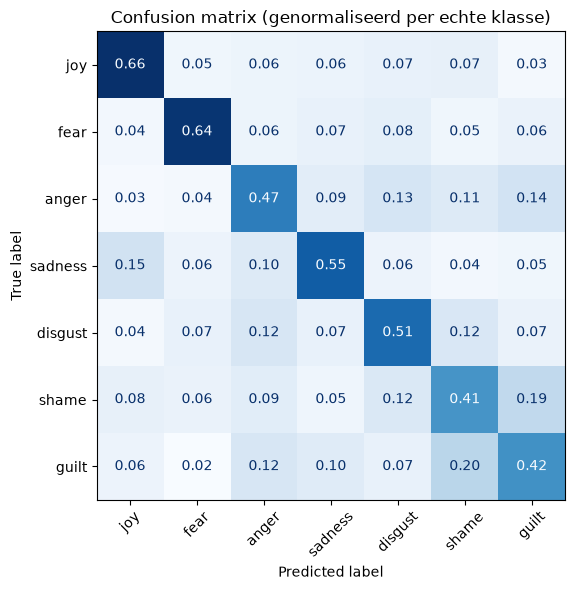

Meest verwarde paren:
     shame <-> guilt    68 fouten
     anger <-> guilt    45 fouten
     anger <-> disgust  43 fouten
   disgust <-> shame    40 fouten
       joy <-> sadness  36 fouten

Top 10 zelfverzekerde fouten:
- echt: anger    voorspeld: guilt    (p=0.99)
  When anybody wants to make me feel guilty. For example: I should do something for my mother, but things didn't go as she hoped. Then she threatens: I'll do it myself.

- echt: anger    voorspeld: shame    (p=0.99)
  While at school I had to write an essay for doing something wrong that I didn't do. I wrote the essay about how I was mistreated and got Saturday morning detention along with a few other kids, but they didn't show up.

- echt: sadness  voorspeld: joy      (p=0.99)
  When I learned that my former boyfriend had become engaged - although I was glad that he had found what he wanted, I was very sad at my own personal loss, since I had always hoped we might one day reconcile.

- echt: sadness  voorspeld: guilt    

In [8]:
# door claude gegenereerd analyse van confusion matrix

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report


def error_analysis(encoder, texts, labels, outcome_space, n_classes=7,
                   seed=0, C=1.0, n_examples=10):
    names = [outcome_space.name(i) for i in range(n_classes)]

    # Gestratificeerde split, zodat elke emotie even vaak in de validatieset zit
    tr_txt, va_txt, y_tr, y_va = train_test_split(
        list(texts), np.array(labels), test_size=0.2,
        stratify=labels, random_state=seed
    )
    X_tr = np.stack([encoder(t) for t in tr_txt])
    X_va = np.stack([encoder(t) for t in va_txt])

    clf = LogisticRegression(C=C, max_iter=2000)
    clf.fit(X_tr, y_tr)
    y_pred = clf.predict(X_va)
    probs = clf.predict_proba(X_va)

    # 1. Scores per klasse
    print(classification_report(y_va, y_pred, labels=list(range(n_classes)),
                                target_names=names, digits=3))

    # 2. Confusion matrix, per rij genormaliseerd: "van de echte X, welk deel werd Y?"
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(
        y_va, y_pred, labels=list(range(n_classes)), display_labels=names,
        normalize="true", values_format=".2f", cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title("Confusion matrix (genormaliseerd per echte klasse)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # 3. Welke paren worden het vaakst verward (in beide richtingen samen)?
    cm = confusion_matrix(y_va, y_pred, labels=list(range(n_classes)))
    pairs = [
        (cm[i, j] + cm[j, i], names[i], names[j])
        for i in range(n_classes) for j in range(i + 1, n_classes)
    ]
    pairs.sort(reverse=True)
    print("Meest verwarde paren:")
    for count, a, b in pairs[:5]:
        print(f"  {a:>8} <-> {b:<8} {count} fouten")

    # 4. Fouten waar het model het zekerst van was
    wrong = np.where(y_pred != y_va)[0]
    confidence = probs[wrong, y_pred[wrong]]
    most_confident = wrong[np.argsort(-confidence)][:n_examples]

    print(f"\nTop {n_examples} zelfverzekerde fouten:")
    for idx in most_confident:
        print(f"- echt: {names[y_va[idx]]:<8} voorspeld: {names[y_pred[idx]]:<8} "
              f"(p={probs[idx, y_pred[idx]]:.2f})")
        print(f"  {' '.join(va_txt[idx].split())}\n")

    return {"clf": clf, "cm": cm, "y_true": y_va, "y_pred": y_pred,
            "texts": va_txt, "probs": probs}


results = error_analysis(
    encoders.BagOfWords(tokenizer), train_texts, train_labels, outcome_space
)